In [ ]:
import pandas as pd
import ast
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()

<Axes: xlabel='job_posted_month_no'>

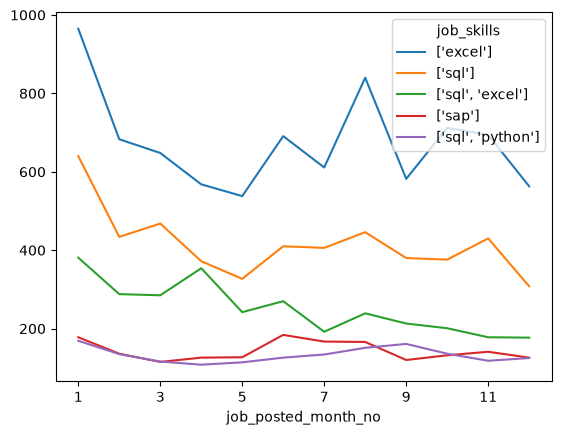

In [21]:
import pandas as pd
from datasets import load_dataset
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])

df_DA = df[df['job_title_short'] == 'Data Analyst'].copy()

df_DA['job_posted_month_no'] = df_DA['job_posted_date'].dt.month

df_DA_explode = df_DA.explode('job_skills')

df_DA_pivot = df_DA_explode.pivot_table(
    index='job_posted_month_no',
    columns='job_skills',
    aggfunc='size',
    fill_value=0
)

df_DA_pivot.loc['total'] = df_DA_pivot.sum()

df_DA_pivot = df_DA_pivot[
    df_DA_pivot.loc['total'].sort_values(ascending=False).index
]

df_DA_pivot = df_DA_pivot.drop('total')

df_DA_pivot.iloc[:, :5].plot(kind="line")

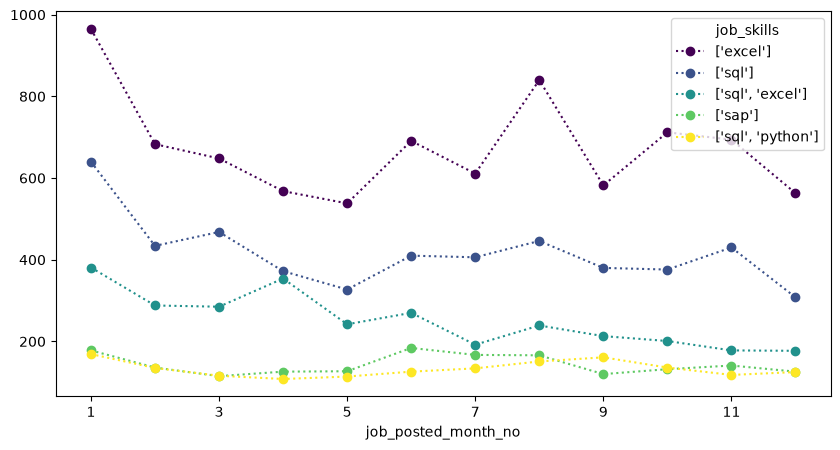

In [22]:
df_DA_pivot.iloc[:, :5].plot(
    kind="line", 
    linestyle=':', # options: '-', '-', '--', '-.', ':'"11_pandas explode.ipynb"
    colormap='viridis', # options: 'viridis', 'plasma', 'inferno', 'magma', 'cividis'"11_pandas explode.ipynb"markersize=5,
    marker='o', # options: 'o', 'x', '+', '*', 's', '.', '1', '2', '3'. '4', ...
    figsize=(10, 5)
)
plt.show()

In [30]:
df_exploded = df_DA.explode('job_skills')

skill_stats = df_exploded.groupby('job_skills').agg(
    median_salary=('salary_year_avg', 'median'),
    skill_count=('job_skills', 'count')
    )
skills_count = 20
skill_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(skills_count)

skill_stats

,median_salary,skill_count
job_skills,,
['excel'],70000.0,8095
['sql'],80000.0,4997
"['sql', 'excel']",90000.0,3020
['sap'],102075.0,1718
"['sql', 'python']",89100.0,1593
['power bi'],72500.0,1577
"['sql', 'tableau']",97500.0,1399
['go'],65000.0,1354
['tableau'],90000.0,1202


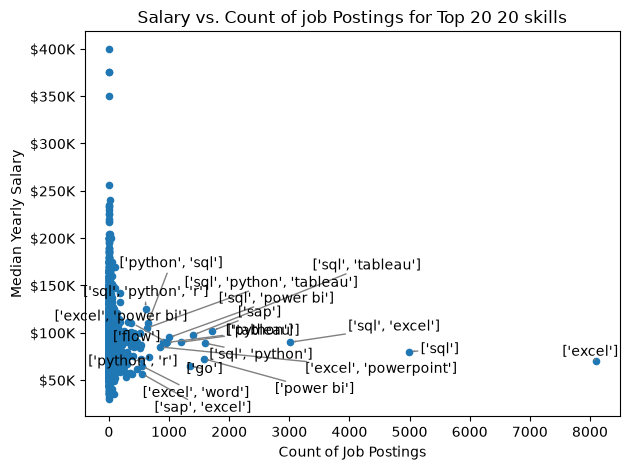

In [38]:
from adjustText import adjust_text

texts = []
skills_stats.plot(kind='scatter', x='skill_count', y='median_salary')

for i, txt in enumerate(skill_stats.index):
    texts.append(plt.text(skill_stats['skill_count'].iloc[i], skill_stats['median_salary'].iloc[i], txt))

adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray'))

ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos: f'${int(y/1000)}K'))

plt.xlabel('Count of Job Postings')
plt.ylabel('Median Yearly Salary')
plt.title(f'Salary vs. Count of job Postings for Top 20 {skills_count} skills')
plt.tight_layout()


plt.show()